# DataFrame and Excel iterator — simplified

[Compare with the full notebook](morphingiterator_example.ipynb).


This alternative keeps the code direct: explicit paths, selected models/scenarios and ordinary calls, without fallback branches or preventive path checks. Run the notebook from the **project root**, with pyfwg, pandas, openpyxl, matplotlib, Jupyter and **Java 17+ on PATH**. Set the paths in the first code cell to your own files. Real regional baselines are required in `EPW_DIR`.

Running all cells starts Java and generates files. Opening the notebook or reading it on Read the Docs displays the saved outputs and figures without running anything. The executed example compares the original EPW with the 2050 and 2080 climate periods; these are not individual forecast years. Parameters are intentionally explicit so you can change them directly.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pyfwg import enable_console_logging

JAR_DIR = Path("F:/Python/pyfwg files")
EPW_DIR = Path("build/cordex-validation/epws").resolve()
OUTPUT_DIR = Path("build/tutorial-simple/morphingiterator_example").resolve()
CACHE_DIR = Path("build/fwg-cache").resolve()
enable_console_logging(level="WARNING")


<StreamHandler stderr (NOTSET)>

## Two regional rows, saved to Excel

Each row has its own JAR, baseline and scenario. The iterator uses the Cordex class for both. This example writes its own `regional-runs.xlsx`; use a different filename for workbooks you edit manually.


In [2]:
from pyfwg import MorphingIterator, MorphingWorkflowCordex, load_runs_from_excel

runs = pd.DataFrame([
    {"epw_paths": str(EPW_DIR / "NAM-44.epw"),
     "fwg_jar_path": str(JAR_DIR / "FutureWeatherGenerator-CORDEX-CMIP5-North-America-NAM-44-v1.2.0.jar"),
     "fwg_rcm_pairs": ["CCCma-CanESM2-SMHI-RCA4"], "fwg_scenarios": ["rcp45"],
     "fwg_model_unzipped_folder": str(CACHE_DIR / "nam-simple"),
     "final_output_dir": str(OUTPUT_DIR / "NAM-44"),
     "temp_base_dir": str(OUTPUT_DIR / "diagnostics/NAM-44"),
     "keyword_mapping": {"region": {"NAM-44": "NAM-44"}}},
    {"epw_paths": str(EPW_DIR / "MNA-22.epw"),
     "fwg_jar_path": str(JAR_DIR / "FutureWeatherGenerator-CORDEX-CMIP5-Middle-East-and-North-Africa-MNA-22-v1.2.0.jar"),
     "fwg_rcm_pairs": ["ICHEC-EC-EARTH-SMHI-RCA4"], "fwg_scenarios": ["rcp85"],
     "fwg_model_unzipped_folder": str(CACHE_DIR / "mna-simple"),
     "final_output_dir": str(OUTPUT_DIR / "MNA-22"),
     "temp_base_dir": str(OUTPUT_DIR / "diagnostics/MNA-22"),
     "keyword_mapping": {"region": {"MNA-22": "MNA-22"}}},
])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
runs.to_excel(OUTPUT_DIR / "regional-runs.xlsx", index=False)
display(runs[["epw_paths", "fwg_rcm_pairs", "fwg_scenarios"]])


,epw_paths,fwg_rcm_pairs,fwg_scenarios
0,D:\Python\pyfwg\build\cordex-validation\epws\N...,[CCCma-CanESM2-SMHI-RCA4],[rcp45]
1,D:\Python\pyfwg\build\cordex-validation\epws\M...,[ICHEC-EC-EARTH-SMHI-RCA4],[rcp85]


## Load, prepare and execute

Use `runs` directly for the DataFrame route, or `load_runs_from_excel` as below for the Excel route. The loader converts the list/dictionary cells back to Python objects.


In [3]:
iterator = MorphingIterator(MorphingWorkflowCordex)
iterator.set_default_values(
    output_filename_pattern="{region}_{rcp}_{year}",
    fwg_create_ensemble=False, fwg_timeframes=[2050, 2080],
    fwg_interpolation_method_id="IDW", fwg_output_profile="MINIMAL",
    fwg_extra_args={"threads": 1, "io_threads": 1}, delete_temp_files=False,
)
runs_from_excel = load_runs_from_excel(str(OUTPUT_DIR / "regional-runs.xlsx"))
iterator.generate_morphing_workflows(runs_from_excel)
display(iterator.morphing_workflows_plan_df[["epw_paths", "fwg_scenarios", "final_output_dir"]])
iterator.run_morphing_workflows(show_tool_output=False)


2026-10-29 14:33:33 - WARNING - Potential file overwrite detected! The following parameters or categories vary between runs but are not included as placeholders in the 'output_filename_pattern': ['fwg_jar_path', 'fwg_rcm_pairs', 'temp_base_dir']. Please add them to the pattern to ensure unique filenames.



          MORPHING CONFIGURATION & PREVIEW
  - FWG JAR Path: F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-North-America-NAM-44-v1.2.0.jar
  - Final Output Directory: D:\Python\pyfwg\build\tutorial-simple\morphingiterator_example\NAM-44
  - EPWs to be Morphed (1 files):
    - NAM-44.epw

  For input file: NAM-44.epw
    -> Generated 'rcp45_2050.epw' will be moved to: D:\Python\pyfwg\build\tutorial-simple\morphingiterator_example\NAM-44\NAM-44_rcp45_2050.epw
    -> Generated 'rcp45_2080.epw' will be moved to: D:\Python\pyfwg\build\tutorial-simple\morphingiterator_example\NAM-44\NAM-44_rcp45_2080.epw
Configuration set. Call execute_morphing() to start the process.

          MORPHING CONFIGURATION & PREVIEW
  - FWG JAR Path: F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-Middle-East-and-North-Africa-MNA-22-v1.2.0.jar
  - Final Output Directory: D:\Python\pyfwg\build\tutorial-simple\morphingiterator_example\MNA-22
  - EPWs to be Morphed (1 files):
    - MNA-22.epw


,epw_paths,fwg_scenarios,final_output_dir
0,D:\Python\pyfwg\build\cordex-validation\epws\N...,[rcp45],D:\Python\pyfwg\build\tutorial-simple\morphing...
1,D:\Python\pyfwg\build\cordex-validation\epws\M...,[rcp85],D:\Python\pyfwg\build\tutorial-simple\morphing...



-------------------- Executing FWG for NAM-44.epw --------------------
  Full Command (for reference): java -jar "F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-North-America-NAM-44-v1.2.0.jar" -g -epw=D:\Python\pyfwg\build\cordex-validation\epws\NAM-44.epw -output_folder=D:\Python\pyfwg\build\tutorial-simple\morphingiterator_example\diagnostics\NAM-44\NAM-44\ -output_layout=ORGANIZED -models=CCCma-CanESM2-SMHI-RCA4 -ensemble=false -temp_shift_winter=0.0 -temp_shift_summer=0.0 -smooth_hours=72 -multithread=true -grid_interpolation_method=IDW -epw_dictionary_limits=true -output_type=EPW -scenarios=rcp45 -timeframes=2050,2080 -output_profile=MINIMAL -model_unzipped_folder=D:\Python\pyfwg\build\fwg-cache\nam-simple -threads=1 -io_threads=1



-------------------- Executing FWG for MNA-22.epw --------------------
  Full Command (for reference): java -jar "F:\Python\pyfwg files\FutureWeatherGenerator-CORDEX-CMIP5-Middle-East-and-North-Africa-MNA-22-v1.2.0.jar" -g -epw=D:\Python\pyfwg\build\cordex-validation\epws\MNA-22.epw -output_folder=D:\Python\pyfwg\build\tutorial-simple\morphingiterator_example\diagnostics\MNA-22\MNA-22\ -output_layout=ORGANIZED -models=ICHEC-EC-EARTH-SMHI-RCA4 -ensemble=false -temp_shift_winter=0.0 -temp_shift_summer=0.0 -smooth_hours=72 -multithread=true -grid_interpolation_method=IDW -epw_dictionary_limits=true -output_type=EPW -scenarios=rcp85 -timeframes=2050,2080 -output_profile=MINIMAL -model_unzipped_folder=D:\Python\pyfwg\build\fwg-cache\mna-simple -threads=1 -io_threads=1


## Compare Toronto

The next cell selects Toronto. To compare Cairo, use `MNA-22.epw`, the `MNA-22` output folder and `rcp85` filenames. Both regions have generated 2050 and 2080 results.


In [4]:
baseline = EPW_DIR / "NAM-44.epw"
future_files = {f"RCP45 · {period}": OUTPUT_DIR / "NAM-44" / f"NAM-44_rcp45_{period}.epw" for period in (2050, 2080)}
comparison_title = "Toronto · NAM-44 · Excel iterator"


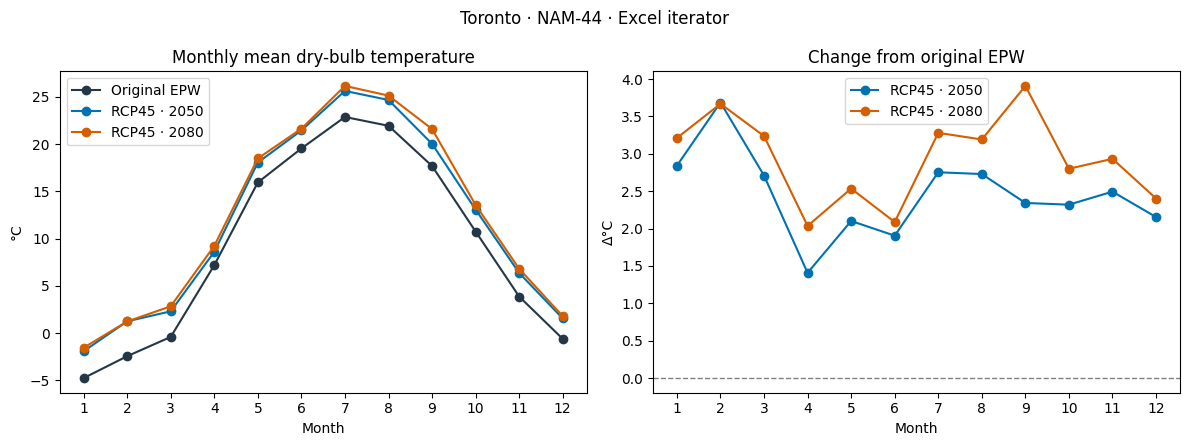

,Original EPW,RCP45 · 2050,RCP45 · 2080
month,,,
1,-4.75,-1.91,-1.54
2,-2.43,1.25,1.24
3,-0.40,2.31,2.84
4,7.19,8.60,9.23
5,15.94,18.04,18.47
6,19.53,21.44,21.62
7,22.86,25.61,26.14
8,21.93,24.66,25.12
9,17.68,20.02,21.59


In [5]:
# Read only month and dry-bulb temperature; 99.9 is the EPW missing code.
climate_files = {"Original EPW": baseline, **future_files}
monthly = pd.DataFrame({
    label: pd.read_csv(path, skiprows=8, header=None, usecols=[1, 6],
                       names=["month", "temperature"], encoding="latin-1",
                       na_values={"temperature": [99.9]}).groupby("month").temperature.mean()
    for label, path in climate_files.items()
})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
monthly.plot(ax=axes[0], marker="o", color=["#243746", "#0072B2", "#D55E00"])
monthly.drop(columns="Original EPW").subtract(monthly["Original EPW"], axis=0).plot(
    ax=axes[1], marker="o", color=["#0072B2", "#D55E00"])
axes[0].set(title="Monthly mean dry-bulb temperature", ylabel="°C", xlabel="Month", xticks=range(1, 13))
axes[1].set(title="Change from original EPW", ylabel="Δ°C", xlabel="Month", xticks=range(1, 13))
axes[1].axhline(0, color="grey", linestyle="--", linewidth=1)
fig.suptitle(comparison_title)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "climate-comparison.png", dpi=160)
plt.show()
display(monthly.round(2))
